In [1]:
%pip install -q gensim scikit-learn matplotlib pandas tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import urllib.request
import zipfile
import shutil
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

ZIP_URL = "https://github.com/NTT123/viwik18/archive/refs/heads/master.zip"

MAX_LINES = 100_000

VECTOR_SIZE = 100
WINDOW = 5
MIN_COUNT = 5
EPOCHS = 5
WORKERS = max(1, os.cpu_count() - 1)

print("Workers:", WORKERS)

Workers: 3


# Install and preprocess dataset

In [4]:
zip_path = DATA_DIR / "viwik18.zip"
repo_dir = DATA_DIR / "viwik18-master"
dataset_dir = repo_dir / "dataset"

if not dataset_dir.exists():
    print("Downloading viwik18...")
    urllib.request.urlretrieve(ZIP_URL, zip_path)

    print("Extracting...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)

print("Dataset folder:", dataset_dir)
print("Number of files:", len(list(dataset_dir.glob("viwik18_*"))))

Extracting...
Dataset folder: data/viwik18-master/dataset
Number of files: 10


In [5]:
token_re = re.compile(r"\w+", flags=re.UNICODE)

def clean_line(line):
    tokens = token_re.findall(line.lower())
    tokens = [t for t in tokens if len(t) >= 2 and not t.isdigit()]
    return tokens

corpus_path = DATA_DIR / "viwik18_clean.txt"

line_count = 0
token_count = 0

with corpus_path.open("w", encoding="utf-8") as out:
    for file_path in tqdm(sorted(dataset_dir.glob("viwik18_*"))):
        with file_path.open("r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                if MAX_LINES is not None and line_count >= MAX_LINES:
                    break

                tokens = clean_line(line)

                if len(tokens) >= 3:
                    out.write(" ".join(tokens) + "\n")
                    token_count += len(tokens)

                line_count += 1

        if MAX_LINES is not None and line_count >= MAX_LINES:
            break

print("Saved corpus:", corpus_path)
print("Lines read:", line_count)
print("Tokens kept:", token_count)

  0%|          | 0/10 [00:00<?, ?it/s]

Saved corpus: data/viwik18_clean.txt
Lines read: 10
Tokens kept: 148259070


# Apply Word2vec

In [6]:
model = Word2Vec(
    corpus_file=str(corpus_path),
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=WORKERS,
    sg=1,          # 1 = Skip-gram, 0 = CBOW
    negative=10,
    epochs=EPOCHS,
    seed=42
)

model_path = OUTPUT_DIR / "viwik18_word2vec.model"
model.save(str(model_path))

print("Saved model:", model_path)
print("Vocabulary size:", len(model.wv))

Saved model: outputs/viwik18_word2vec.model
Vocabulary size: 288094


In [7]:
words = ["việt", "nam", "hà", "nội", "mỹ", "pháp", "kinh", "tế", "văn", "học"]

for word in words:
    if word in model.wv:
        print(f"\nMost similar to '{word}':")
        for similar_word, score in model.wv.most_similar(word, topn=10):
            print(similar_word, round(score, 4))
    else:
        print(f"\n'{word}' không có trong vocabulary")


Most similar to 'việt':
lđlđ 0.755
míttinh 0.747
việtnam 0.7458
nứơc 0.7425
cămpuchia 0.7416
vtvn 0.7404
tnxp 0.7342
vnqdđ 0.733
apganistan 0.7309
iên 0.7267

Most similar to 'nam':
bắc 0.8165
đông 0.7976
onsong 0.7247
miền 0.7152
tây 0.7019
hyongjesan 0.6996
tâ 0.6909
hwacheon 0.6894
ryongsong 0.6883
trung 0.6872

Most similar to 'hà':
lan 0.7522
đhsp 0.7364
vân 0.7329
hoài 0.7311
giang 0.7269
kolomenskoye 0.7154
tĩnh 0.7141
chiển 0.7136
ội 0.7113
gdck 0.7097

Most similar to 'nội':
gdck 0.7742
đhsp 0.7632
chiển 0.7486
đhbk 0.7352
bảnnn 0.7303
dilmah 0.7278
vỵ 0.7211
đvsktt 0.7207
hunsen 0.7084
taolu 0.705

Most similar to 'mỹ':
mĩ 0.8513
canađa 0.729
emea 0.7175
châu 0.7161
seatle 0.7145
angieri 0.7117
phillipines 0.7088
bantry 0.7054
miều 0.7049
berwich 0.7047

Most similar to 'pháp':
thêm 0.6962
alsace 0.674
xem 0.6723
germinois 0.6619
nam 0.6502
vexin 0.6475
xã 0.6456
mouzon 0.6434
fontenay 0.6425
carros 0.6385

Most similar to 'kinh':
tế 0.8012
doán 0.7091
xă 0.7071
nghành 0.701

In [8]:
seed_words = ["việt", "nam", "hà", "nội", "mỹ", "pháp", "kinh", "tế", "văn", "học", "lịch", "sử"]

selected_words = []

for word in seed_words:
    if word in model.wv and word not in selected_words:
        selected_words.append(word)

        for neighbor, score in model.wv.most_similar(word, topn=8):
            if neighbor not in selected_words:
                selected_words.append(neighbor)

print("Number of words to visualize:", len(selected_words))
print(selected_words[:30])

Number of words to visualize: 87
['việt', 'lđlđ', 'míttinh', 'việtnam', 'nứơc', 'cămpuchia', 'vtvn', 'tnxp', 'vnqdđ', 'nam', 'bắc', 'đông', 'onsong', 'miền', 'tây', 'hyongjesan', 'tâ', 'hwacheon', 'hà', 'lan', 'đhsp', 'vân', 'hoài', 'giang', 'kolomenskoye', 'tĩnh', 'chiển', 'nội', 'gdck', 'đhbk']


# Embedding visualization

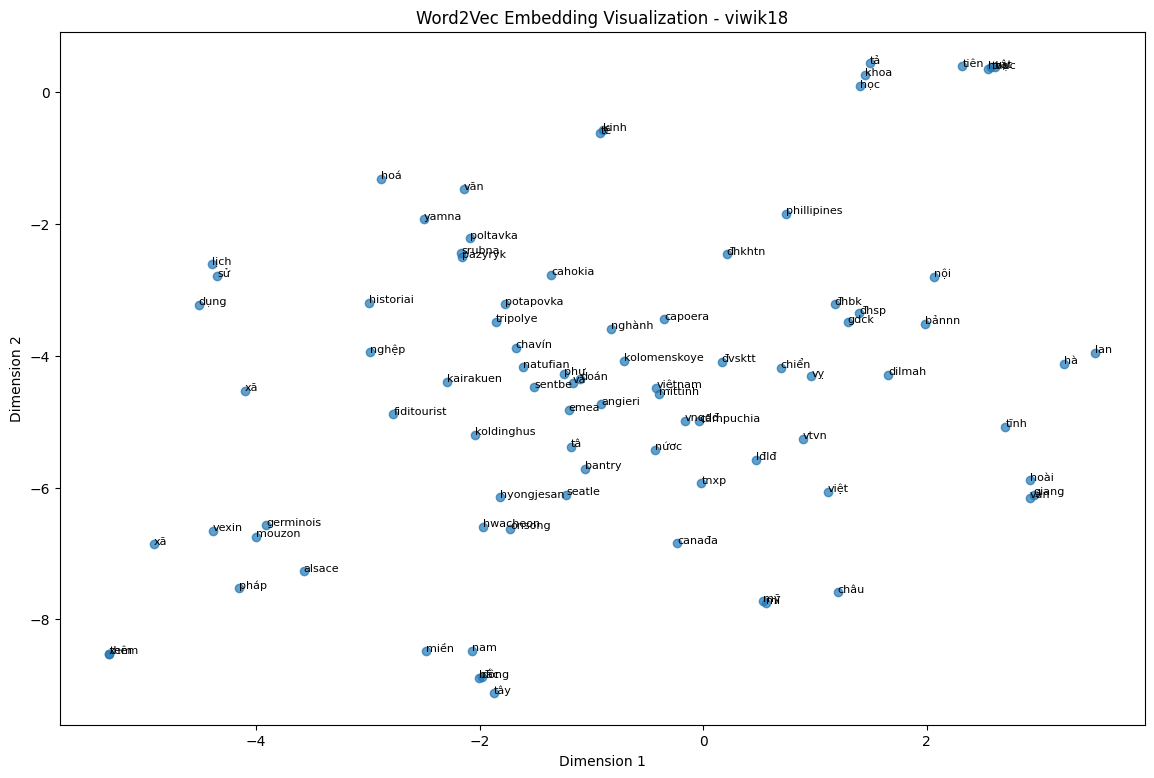

In [9]:
vectors = np.array([model.wv[word] for word in selected_words])

pca = PCA(n_components=min(50, len(selected_words) - 1), random_state=42)
vectors_pca = pca.fit_transform(vectors)

tsne = TSNE(
    n_components=2,
    perplexity=min(30, max(2, len(selected_words)//3)),
    init="pca",
    learning_rate="auto",
    random_state=42
)

vectors_2d = tsne.fit_transform(vectors_pca)

plt.figure(figsize=(14, 9))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.7)

for word, (x, y) in zip(selected_words, vectors_2d):
    plt.text(x, y, word, fontsize=8)

plt.title("Word2Vec Embedding Visualization - viwik18")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

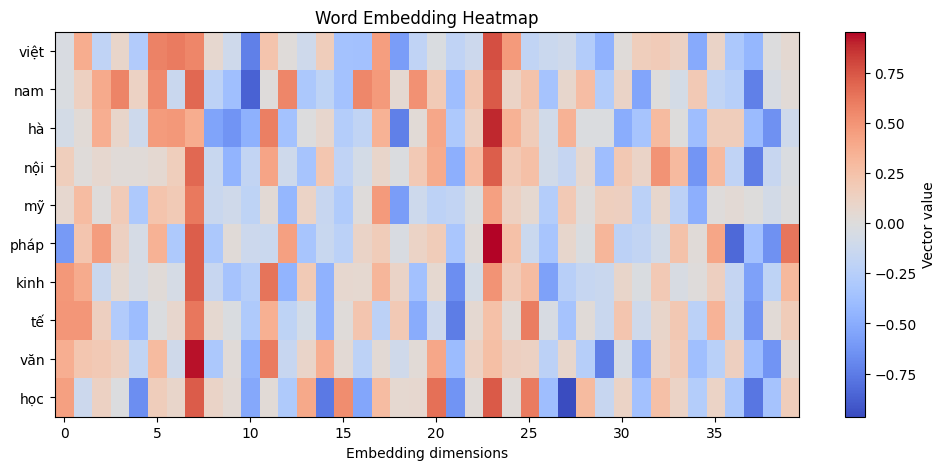

In [10]:
heatmap_words = [w for w in seed_words if w in model.wv][:10]

matrix = np.array([model.wv[w] for w in heatmap_words])
matrix = matrix[:, :40]  # chỉ lấy 40 chiều đầu để dễ nhìn

plt.figure(figsize=(12, 5))
plt.imshow(matrix, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Vector value")
plt.yticks(range(len(heatmap_words)), heatmap_words)
plt.xlabel("Embedding dimensions")
plt.title("Word Embedding Heatmap")
plt.show()